# Center, Spread, Normal Distribution

This content is based on Lecture 25: Center and Spread, Lecture 26: Normal Distribution and Lecture 27: Sample Means. 

**Helpful Resource:**
- [Python Reference](http://data8.org/sp22/python-reference.html): Cheat sheet of helpful array & table methods used in Data 8!

**Recommended Readings**: 
- [Mean and Median](https://inferentialthinking.com/chapters/14/1/Properties_of_the_Mean.html#)
- [Standard Deviation](https://inferentialthinking.com/chapters/14/2/Variability.html)
- [Central Limit Theorem for proportions](https://inferentialthinking.com/chapters/14/4/Central_Limit_Theorem.html)
- [Central Limit Theorem for Sample Means](https://inferentialthinking.com/chapters/14/5/Variability_of_the_Sample_Mean.html)

In [3]:
# These lines import the Numpy and Datascience modules.
import numpy as np
from datascience import *
from scipy import stats
from numpy import sqrt
# These lines do some fancy plotting magic.
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter('ignore')

### Why the Mean Matters?

**Reason**: The empirical distribution of the sample mean has almost always turned out close to bell-shaped, regardless of the population being studied.

With minimal assumptions about the underlying populations, we study the means in the following aspects:

1. What exactly does the mean measure?
2. How close to the mean are most of the data?
3. How is the sample size related to the variability of the sample mean?
4. Why do empirical distributions of random sample means come out bell shaped?
5. How can we use sample means effectively for inference?

### The Mean and the Histogram

"**if two collections have the same distribution, then they have the same mean.**"

To be exact, when we have 2 collections of numerical values - collection A and collection B, if A and B share the **exact same unique numerical values** and each of the unique numerical values in A and B shares the **exact same proportion**, the **mean of A will equal the mean of B**. 

The mean of a collection depends only on the distinct values and their proportions, not on the number of elements in the collection. In other words, the mean of a collection depends only on the distribution of values in the collection.

In [ ]:
small_collection = make_array(30, 40, 50, 50, 66, 66, 66, 90)
fulcrum_mean_1 = np.mean(small_collection)
fulcrum_mean_1

In [ ]:
big_collection = make_array(66, 50, 50, 50, 50, 66, 66, 66, 30, 30, 66, 40, 90, 40, 66, 90)
fulcrum_mean_2 = np.mean(big_collection)
fulcrum_mean_2

So the order of the items in each collection doesn't matter. What matters are the **exact same unique numerical values** and the **exact same proportion**.

Collection A and collection B will have the exact same histogram because histogram captures the **density of the distribution** in the collections, **not the exact amount** of the collections.

In [ ]:
small_collection = Table().with_columns('Value', small_collection)
small_collection.hist()

In [ ]:
big_collection = Table().with_columns('Value', big_collection)
big_collection.hist()

"**The mean is the center of gravity or balance point of the histogram.**"

In [ ]:
big_collection.hist()
plots.plot([27, 93], [0, 0], color='green', lw=5)
plots.scatter(fulcrum_mean_2, -0.0015, marker='^', color='red', s=100)
plots.title('Average as a Center of Gravity');
print(f"fulcrum_mean: {fulcrum_mean_2}")

### The Mean and the Median

"In general, **for symmetric distributions, the mean and the median are equal.**"

If the histogram has a tail on one side (the formal term is “skewed”), then the mean is pulled away from the median in the direction of the tail.

In [ ]:
symmetric = make_array(2, 3, 3, 4)
non_symmetric = make_array(2, 3, 3, 9)

# mean
sym_mean = np.mean(symmetric)
non_sym_mean = np.mean(non_symmetric)
(sym_mean, non_sym_mean)

In [ ]:
# median
sym_median = percentile(50, symmetric)
non_sym_median = percentile(50, non_symmetric)
(sym_median, non_sym_median)

In [ ]:
sym_tbl = Table().with_columns('Value', symmetric).hist(bins=np.arange(0.5, 12, 1))
#plots.plot([1, 10], [0, 0], color='green', lw=5)
plots.scatter(sym_mean, -0.015, marker='^', color='red', s=100)
plots.title('Average as a Center of Gravity');
print(f"sym_mean: {sym_mean}")

In [ ]:
non_sym_tbl = Table().with_columns('Value', non_symmetric).hist(bins=np.arange(0.5, 12, 1))
#plots.plot([1, 10], [0, 0], color='green', lw=5)
plots.scatter(non_sym_mean, -0.015, marker='^', color='red', s=100)
plots.title('Average as a Center of Gravity');
print(f"non_sym_mean: {non_sym_mean}")

In [ ]:
# let's overlay the histogram to compare
both_tbl = Table().with_columns('Sym Value', symmetric, 'Non Sym Value', non_symmetric).hist(bins=np.arange(0.5, 12, 1), alpha=0.6)
plots.scatter(non_sym_mean, -0.015, marker='^', color='green', s=100, label='non sym mean')
plots.scatter(sym_mean, -0.015, marker='^', color='red', s=100, label='sym mean')
plots.title('Average as a Center of Gravity');
plots.legend()
print(f"non_sym_mean: {non_sym_mean}")
print(f"sym_mean: {sym_mean}")

#### Example of Mean and Median - Tech Salaries

In [ ]:
tech_salaries = Table.read_table('tech_salaries.csv')
tech_salaries.hist('Salary', bins=np.arange(30000, 700001, 25000))

In [ ]:
# Median
salary_median = percentile(50, tech_salaries.column('Salary'))
salary_median

In [ ]:
# Mean
salary_mean = np.mean(tech_salaries.column('Salary'))
salary_mean

In [ ]:
# check the overall data distribution
tech_salaries.hist('Salary', bins=np.arange(30000, 700001, 25000))
#plots.scatter(median, -0.025, marker='^', color='green', s=50)
#plots.scatter(mean, -0.015, marker='^', color='red', s=100)
plots.axvline(salary_median, color='lightgreen', linestyle='--', linewidth=2, label='Median Salary')
plots.axvline(salary_mean, color='red', linestyle='--', linewidth=2, label='Mean Salary')
plots.legend()
print(f"salary_median: {salary_median}")
print(f"salary_mean: {salary_mean}")

### Standard Deviations (SD) from Average

1. calculate the _average_ (mean) a collection of numerical values
2. calculate the _deviations_ from average for each numercial value in the collection that simply subtract the average from each numerical value in the collection
3. _square_ the deviations from average
4. calculate the _mean_ of the squared deviation from average that is called variance
5. take a positive square _root_ of the variance

"**By definition, the SD of a list is defined as the root mean square of deviations from average. That’s a mouthful. But read it from right to left and you have the sequence of steps in the calculation.**"

In [ ]:
# Standard Deviation:    root mean squared deviation from average
# Steps of calculation:   5    4      3       2             1

#### Use Numpy `np.std()` Function

In [ ]:
# calculate the average (mean) a collection of numerical values
small_collection = make_array(30, 40, 50, 50, 66, 66, 66, 90)
mean = np.mean(small_collection)
mean

In [ ]:
# calculate the deviations from average
deviations = small_collection - mean
sd_process_tbl = Table().with_columns(
    'Value', small_collection, 
    'Deviation from Average', deviations
)
sd_process_tbl

In [ ]:
# square the deviations from average
squared_deviations = deviations ** 2
sd_process_tbl = sd_process_tbl.with_column(
   'Squared Deviations from Average', squared_deviations
    )
sd_process_tbl

In [ ]:
# calculate the mean of the squared deviation from average that is called variance
variance = np.mean(squared_deviations)
variance

In [ ]:
# take a positive square root of the variance
sd = variance ** 0.5
sd

In [ ]:
np.std(small_collection)

In [ ]:
salary_sd = np.std(tech_salaries.column('Salary'))
salary_sd

### Exercise: Mean, Median, Standard Deviation (Optional)

Find the mean, median and standard deviation of the following data set: 19, 19, 20, 22. Do your work either on paper or using the Python command line *without* the use of ```np.median``` and ```np.sd``` 

Note: the formula for standard deviation is $SD = \sqrt{\frac{\sum_i (x_i - \bar{x})^2}{n}}$

### Chebychev’s Bounds

For all datasets and their distributions, the proportion of data points that are in the range of plus and minus $\pm$ $z$ standard deviations of mean is at least $$1 - \frac{1}{z^2}$$
where $z$ is the number of standard deviation, assuming $z$ > 1.

So, Chebychev’s Bounds are applicable to all distributions, no matter how irregular.

- the proportion in the range “average ± 2 SDs” is at least 1 - 1/4 = 0.75

- the proportion in the range “average ± 3 SDs” is at least $1 - \frac{1}{9} \approx 0.89$

- the proportion in the range “average ± 4.5 SDs” is at least $1 - \frac{1}{4.5^2} \approx 0.95$

#### Apply Chebychev’s Bounds to Salaries Distribution

Given a highly right-skewed Silicon Valley salary distribution where

$$\text{Mean} \approx \$260,000$, $\text{SD} \approx \$80,000$$

We evaluate the engineering employees salaries range from $\$100,000$ to $\$420,000$.

The distance in standard units ($z$) is:
$$z = \frac{420,000 - 260,000}{80,000} = 2$$

Applying Chebyshev's Bound, the proportion of software engineers within $z = \pm 2$ standard deviations is at least:
$$1 - \frac{1}{2^2} = 1 - \frac{1}{4} = 0.75 \text{ (or 75\%)}$$

#### Apply Chebyshev’s Bounds to a Symmetric Dataset

Let's try the symmetic dataset.

In [ ]:
symmetric = make_array(2, 3, 3, 4)
mean = np.mean(symmetric)
mean

In [ ]:
sd = np.std(symmetric)
sd

In [ ]:
# z = 2
lower_bound = mean - (sd * 2)
upper_bound = mean + (sd * 2)
(lower_bound, upper_bound)

In [ ]:
# calculate the proportion in the range “average ± 2 SDs”
z = 2
two_sd = 1 - (1 / pow(2, 2))
two_sd

75% of the entries in the dataset has a value of 1.59 or above. In this small dataset (2, 3, 3, 4), 75% covers all entries.

### Standard Units

The quantity $z$ measures standard units, meaning the number of standard deviations above average.

To convert a value to standard units,
$$z = \frac{\text{value} - \text{average}}{\text{SD}}$$

The goal is to produce 0 mean and 1 standard deviation for the numerical values that we want to compare.


In [ ]:
# create a function calculate standard units
def standard_units(numbers_array):
    "Convert any array of numbers to standard units."
    return (numbers_array - np.mean(numbers_array))/np.std(numbers_array)  

In [ ]:
years_comp = Table.read_table('experience_vs_compensation.csv')
years_comp.show(3)

In [ ]:
years_standard_units = standard_units(years_comp.column('Experience_Years'))
#years_standard_units

In [ ]:
comp_standard_units = standard_units(years_comp.column('Total_Compensation_USD'))
#comp_standard_units

In [ ]:
years_comp_su = years_comp.with_columns(
    'Years_SU', years_standard_units,
    'Salary_SU', comp_standard_units
)
years_comp_su.show(10)

Remember, the goal of standard unit conversion is to produce 0 mean and 1 standard deviation for the numerical values that we want to compare.

Let's check the mean and the standard deviation.

In [ ]:
np.mean(years_standard_units), np.std(years_standard_units)

In [ ]:
np.mean(comp_standard_units), np.std(comp_standard_units)

In [ ]:
np.round(np.mean(years_standard_units), 4), np.round(np.std(years_standard_units), 4)

In [ ]:
np.round(np.mean(comp_standard_units), 4), np.round(np.std(comp_standard_units), 4)

In [ ]:
Table().with_columns('Years SU (z)', years_standard_units, 'Salary SU (z)', comp_standard_units).hist(alpha=0.5)

### The SD and the Normal Curve

#### Bell-Shaped Disribution

A good example to demonstrate a bell-shaped curve is the cars distribution in a mall parking lot. Typically, during rush hours, most of the cars are parked near the main entrance and then eventually scattered away to the left and right of the entrance.

In [ ]:
# negative numbers represent the cars parked on the left, 
#   bigger the number further away from the entrance to the left.
# positive numbers represent the cars parked on the right, 
#   bigger the number further away from the entrance to the right.
parking_lot = Table.read_table('parking_lot_distribution.csv')
parking_lot.show(7)

In [ ]:
parking_lot.hist('Stall_Position_Rows', bins=np.arange(-18, 19, 1))

plots.title("Bell-Shaped Distribution - Density of Parked Cars")
plots.xlabel("Stall Position (Rows relative to Main Entrance)")
plots.show()

In [ ]:
mean = np.mean(parking_lot.column('Stall_Position_Rows'))
median = percentile(50, parking_lot.column('Stall_Position_Rows'))
sd = np.std(parking_lot.column('Stall_Position_Rows'))
print(f"mean: {mean}, median: {median}, sd: {sd}")

The mean is a little bigger than the median which represents the distribution of cars is slightly shifted or stretched out into the right-hand wing of the mall property

"**In general, for bell-shaped distributions, the SD is the distance between the mean and the points of inflection on either side.**"

#### Let's take a look at the bell-shaped distribution using standard units (z)

In [ ]:
Table().with_columns('Parking SU (z)', standard_units(parking_lot.column('Stall_Position_Rows'))).hist()

### The standard normal curve

"The standard normal curve has an impressive equation. But for now, it is best to think of it as a smoothed outline of a histogram of a variable that has been measured in standard units and has a bell-shaped distribution."

<img src='standard-normal-curve.png' alt='standard-normal-curve' width=500/>

#### How to read the standard normal curve?

1. The total area under the curve is 1. So you can think of it as a histogram drawn to the density scale.
2. The curve is symmetric about 0. So if a variable has this distribution, its mean and median are both 0.
3. The points of inflection of the curve are at -1 and +1.
4. If a variable has this distribution, its SD is 1. The normal curve is one of the very few distributions that has an SD so clearly identifiable on the histogram.

For some mathematical reasons (calculus), areas under the curve have to be approximated.

In Python, we import `stats` method from `scipy` to approximate the areas under the standard normal curve.

`from scipy import stats` only works on a perfectly symmetrical bell-shaped curve.

Details refer to <a href='https://inferentialthinking.com/chapters/14/3/sd-and-the-normal-curve/#the-standard-normal-cdf' target='_blank'>The standard normal "cdf"</a> on the textbook.

### The Central Limit Theorem (CLT)

**"The Central Limit Theorem says that the probability distribution of the sum or average of a large random sample drawn with replacement will be roughly normal, regardless of the distribution of the population from which the sample is drawn."**

The Central Limit Theorem makes it possible to make inferences with very little knowledge about the population, provided we have a large random sample. That is why it is central to the field of statistical inference.

"In other words, if the test statistic is a **simple sum**, a **simple average**, or a **binary proportion**, we can use the Central Limit Theorem to make an inference about the sampling distribution of that test statistic."

#### Apply Central Limit Theorem to Tech Salaries

Let's use the Tech Salaries dataset as a sandbox to demonstrate the magic of the Central Limit Theorem.

In [ ]:
tech_salaries = Table.read_table("tech_salaries.csv")
tech_salaries.hist('Salary', bins=np.arange(30000, 700001, 25000))

As we can see, the salary distribution is highly right-skewed with long right tail.

In [ ]:
# let's create a function to calculate a mean what works for all data tables
def one_bootstrap_mean(table, coluum_name):
    re_sample = table.sample()
    return np.average(re_sample.column(coluum_name))

In [ ]:
# let's create function simulate the bootstrap the difference of 2 means many times
#   the function parameter list: table, column name and repeats
def simulate_bootstrap_mean(table, column_name, repeats):
    bootstrap_means = make_array()
    for i in np.arange(repeats):
        re_sampled_mean = one_bootstrap_mean(table, column_name)
        bootstrap_means = np.append(bootstrap_means, re_sampled_mean)
    return bootstrap_means

In [ ]:
# select the original sample from population
original_sample = tech_salaries.sample(700, with_replacement=False)
bootstrapped_statistics = simulate_bootstrap_mean(original_sample, 'Salary', 5000)
(max(bootstrapped_statistics), min(bootstrapped_statistics))

In [ ]:
sampled_means = Table().with_column('Bootstrap Sample Mean 700', bootstrapped_statistics)
bins_size =np.arange(190000, 220001, 1000)
sampled_means.hist(bins = bins_size)

# Plotting parameters; you can ignore this code
#plots.ylim(-0.000005, 0.00014)
plots.ylim(0.0, 0.00010)
#parameter_green = '#32CD32'
#plots.scatter(salary_median, 0, color=parameter_green, s=40, zorder=2);
#plots.axvline(salary_median, color='red', linestyle='--', linewidth=2, label='Observed Data')
#plots.axvline(original_sample_median, color='red', linestyle='--', linewidth=2, label='Observed Data')
plots.legend()

To overlay the perfect bell curve (CLT), let's calculate the mean and the standard deviation from the original sample. In reality, we the original sample is all we have for bootstrapping.

Then, we use `stats.norm.pdf()` function to draw the perfect bell curve.

In [ ]:
sample_size = original_sample.num_rows
clt_mean = np.mean(original_sample.column('Salary'))
# calculate the spread of the sample average
clt_std = np.std(original_sample.column('Salary')) / np.sqrt(sample_size)
(clt_mean, clt_std)

In [ ]:
sampled_means = Table().with_column('Bootstrap Sample Mean', bootstrapped_statistics)
bins_size =np.arange(190000, 220001, 1000)
sampled_means.hist(bins = bins_size)
plots.ylim(0.0, 0.00010)

x_axis = np.linspace(190000, 220000, 500)
y_axis_curve = stats.norm.pdf(x_axis, loc=clt_mean, scale=clt_std)
plots.plot(x_axis, y_axis_curve, color='red', linewidth=3, label='CLT Normal Model')
plots.legend()

### The Variability of the Sample Mean

Let's simulate the mean of a random sample of 1400, 2300 and 4000 salaries. We will perform 5000 repetitions of each of these process. We want to check out the similarities and differences of the mean when using different random sample size.

In [ ]:
"""Empirical distribution of random sample means"""

def simulate_sample_mean(table, label, sample_size, repetitions):
    
    means = make_array()

    for i in range(repetitions):
        new_sample = table.sample(sample_size)
        new_sample_mean = np.mean(new_sample.column(label))
        means = np.append(means, new_sample_mean)

    sample_means = Table().with_column('Sample Means', means)
    
    # Display empirical histogram and print all relevant quantities
    sample_means.hist(bins=20)
    plots.xlabel('Sample Means')
    plots.title('Sample Size ' + str(sample_size))
    print("Sample size: ", sample_size)
    print("Population mean:", np.mean(table.column(label)))
    print("Average of sample means: ", np.mean(means))
    print("Population SD:", np.std(table.column(label)))
    print("SD of sample means:", np.std(means))

In [ ]:
simulate_sample_mean(tech_salaries, 'Salary', 1400, 5000)

plots.ylim(0.0, 0.00020)
plots.legend()

In [ ]:
simulate_sample_mean(tech_salaries, 'Salary', 2300, 5000)

plots.ylim(0.0, 0.00020)
plots.legend()

In [ ]:
simulate_sample_mean(tech_salaries, 'Salary', 4000, 5000)

plots.ylim(0.0, 0.00020)
plots.legend()

### The SD of All the Sample Means

From the variability of the sample mean above, we notice that:

1. We can see the Central Limit Theorem in action – the histograms of the sample means are roughly normal, even though the histogram of the tech salaries dataset is far from normal.

2. We can also see that each of the three histograms of the sample means is centered very close to the population mean. In each case, the “average of sample means” is very close to $208518, the population mean.

3. We also notice that bigger the sample size, the narrower and taller the histogram is.

4. We further notice that the bigger the sample size, the smaller the standard deviation is.

"The probability distribution of the sample mean is based on the means of all possible samples of a fixed size."

If the samples are drawn at random with replacement from the population, then
$$\text{Standard Deviation of all possible sample means} = \frac{\text{Population SD}}{\sqrt{\text{Sample Size}}}$$

This is the standard deviation of the averages of all the possible samples that could be drawn. It measures roughly how far off the sample means are from the population mean.

#### What does "The SD of All the Sample Means" apply to the tech salary example?

We have over 40,000 salary entries in the dataset. If we are to take 700 random samples from the dataset and calculate the average salary each time, there will be millions of possible combinations of 700 random samples. That means we will have millions of averages salary. When we draw a histogram of all those millions of averages, it contains the SD of all the sample means. In other words, it is the spread of the sample average.

In [ ]:
# draw random sample from the sandbox salaries dataset
tech_salaries_700 = tech_salaries.sample(700, with_replacement=False)
pop_std = np.std(tech_salaries_700.column('Salary'))
sd_all_sample_means = pop_std / np.sqrt(700)
print(f"sd_all_sample_means: {sd_all_sample_means}")
print(f"pop_std: {pop_std}")

Record, "**The Central Limit Theorem says that the probability distribution of the sum or average of a large random sample drawn with replacement will be roughly normal, regardless of the distribution of the population from which the sample is drawn.**"

Because we have a roughly normal distribution and know the SD of all the sample means, we can measure rougly how far off the sample means are from the population mean.

In summary, the Central Limit Theorem is a mathematical truth for analytical prediction. The simulation is the empirical experimental proof.

### An example of Central Limit Theorem for Sample Proportions

Remember that "if the test statistic is a **simple sum**, a **simple average**, or a **binary proportion**, we can use the Central Limit Theorem to make an inference about the sampling distribution of that test statistic." We also know that proportion is also mean, and that applies only to binary proportion (2 categories). For example, 0s and 1s, true and false.

#### Electric Vehcial Charging Stations

A regional environmental agency wants to estimate the true proportion of public electric vehicle (EV) charging stations in a state that are broken or malfunctioning on any given day. They inspect a random sample of 250 stations across the state. In their dataset, they record a 1 if the station is broken and a 0 if it is working perfectly. Out of the 250 audited stations, 35 are broken which 14%.

The company expects the broken proportion will be 14% if they inspect a larger randon sample.

Again proportions are means, the Central Limit Theorem says that the distribution of the random sample drawn with replacement will be roughly normal, regardless of the distribution of the population from which the sample is drawn.

Let's check it with simulation.

In [84]:
ev_audit = Table.read_table('ev_charging_audit.csv')
ev_audit.show(3)

Is_Broken
1
1
1


In [85]:
ev_audit.group('Is_Broken')

Is_Broken,count
0,215
1,35


In [86]:
proportions_1 = make_array()

num_ev_stations = 600
repeats = 10000

for i in np.arange(repeats):
    sample = ev_audit.sample(num_ev_stations)
    new_proportion = np.count_nonzero(sample.column('Is_Broken') == 1) / num_ev_stations
    proportions_1 = np.append(proportions_1, new_proportion)
    
results = Table().with_column('Sample Proportion: 400', proportions_1)

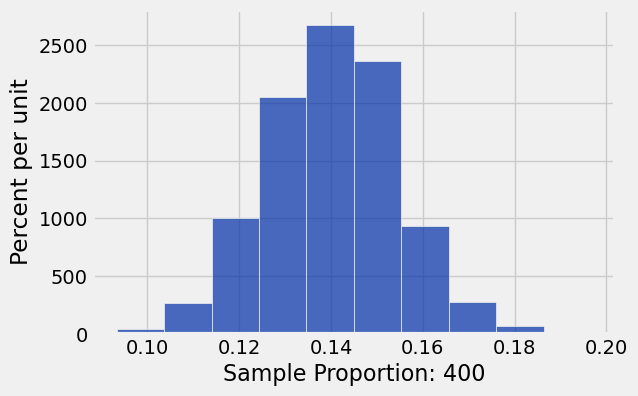

In [87]:
results.hist()

In [88]:
proportions_2 = make_array()

num_ev_stations = 2400
repeats = 10000

for i in np.arange(repeats):
    sample = ev_audit.sample(num_ev_stations)
    new_proportion = np.count_nonzero(sample.column('Is_Broken') == 1)/num_ev_stations
    proportions_2 = np.append(proportions_2, new_proportion)
    
results = results.with_column('Sample Proportion: 1600', proportions_2)

In [89]:
results

Sample Proportion: 400,Sample Proportion: 1600
0.143333,0.145417
0.115,0.134167
0.148333,0.13875
0.13,0.1475
0.135,0.145
0.125,0.14
0.138333,0.134583
0.163333,0.135
0.151667,0.146667
0.111667,0.1475


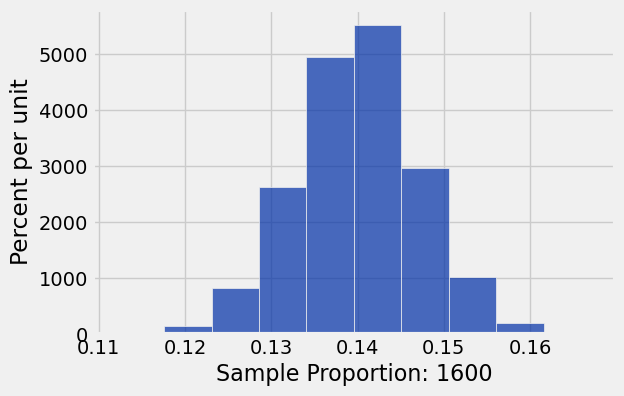

In [90]:
results.hist('Sample Proportion: 1600')

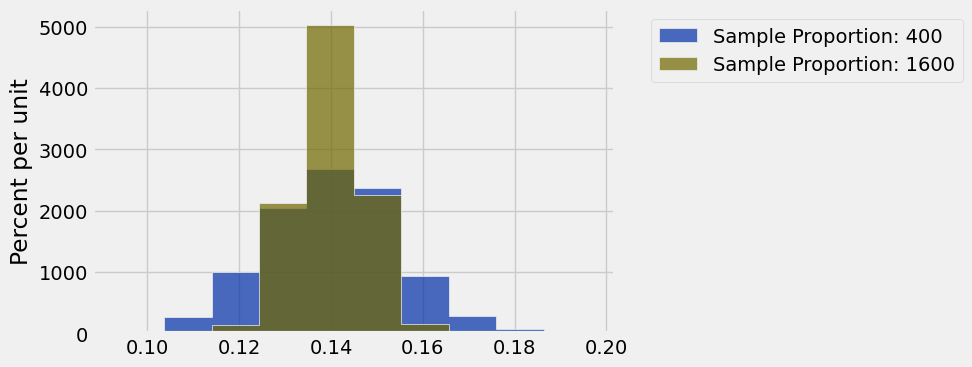

In [91]:
results.hist()